# Hybrid modelling of leaf traits: PINN demo (Sun et al. 2025)

**Paper:** Sun, P., van Bodegom, P. M., Timmermans, J., Liu, S., Wu, J., & Visser, M. D. (2025).
*Hybrid modelling of leaf traits: Integrating neural networks with radiative transfer theory.*
**Remote Sensing of Environment 329:114958**, DOI [10.1016/j.rse.2025.114958](https://doi.org/10.1016/j.rse.2025.114958)

**Author code (pinned):** [Schimasuperbra/hybrid-leaf-traits-pinn](https://github.com/Schimasuperbra/hybrid-leaf-traits-pinn) @ commit `7b8d143900a9638a89d419e2beb9c8cd1a015303` (MIT license), `SI_code_PINN.ipynb`.
**Data (pinned):** Zenodo record [22092672](https://zenodo.org/records/22092672) (latest version of concept 22078997), `data.zip` 88,415,162 bytes, md5 `d9157f9bcf1b10d61c352c59e7d47b19`, CC-BY-4.0.

**Purpose.** Train the paper's Physics-Informed Neural Network — a multi-head attention **encoder** that maps a leaf reflectance spectrum to six PROSPECT5 traits (N, Cab, Car, Cbrown, Cw, Cm), decoded back to spectra by a differentiable **PROSPECT5B radiative-transfer decoder** — on the LOPEX + ANGERS labeled datasets and unlabeled spectra, then inspect leaf-trait predictions on the held-out validation sites (FFT, BELJAP, IFGG, BEL, BNL).

**Scope (partial demonstration, not full-paper reproduction).**
- Executed: one seed, ~1000 training epochs (README "quick demo"; the paper used 20,000 epochs), the **default full-physics decoder** variant, loss curves, and observed-vs-predicted validation plots.
- Out of scope: the MCMC (emcee) and PLSR benchmarks (`SI_code_benchmarks.ipynb`), the CNN-replaced decoder variants (`Decoder_tran/plate/both`), 5-seed averaging, and paper-level accuracy claims. A single small run does not verify published dataset-level scores.

**Adaptations (all documented AI-authored edits to author code):** single seed 55 (author looped seeds 55–59); `range(nepochs)` instead of the hard-coded 20,000; `Decoder()` instead of the `Decoder_tran()` instantiation in the author's training cell; progress/eval every 250 epochs; a Colab data-download cell; a compact dataset check instead of the per-column scan.

**実行状態：** このノートブックは実際にGoogle Colab (T4 GPU) で最初から最後まで実行・検証されています。ただし部分的なデモンストレーションであり、論文の完全な再現ではありません。論文は20,000エポック学習していますが、本デモはREADMEのクイックデモ相当の約1,000エポックです。


## Runtime selection — run this on a **T4 GPU**

`Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all`.

- The authors recommend CUDA for the PINNs; the code auto-selects `cuda:0` if available, else CPU.
- Expected: ~89 MB (torchrtm wheel) + 88 MB (data.zip) downloads, and a few minutes total on T4.
- **Recommended: T4 GPU.** CPU would also run but was not validated for this demo and is slower.

**Japanese:** 上部メニュー「ランタイム → ランタイムのタイプを変更」で **T4 GPU** を選択してから「すべてのセルを実行」してください。ダウンロードは約180 MB、T4では数分で完了する見込みです（CPU未検証）。


## Setup dependencies

The author's environment is Python 3.10 with `torch`, `torchrtm` (the differentiable PROSPECT5B backend, which ships the absorption coefficient matrix), numpy/pandas/scipy/scikit-learn/matplotlib/seaborn. Colab preinstalls everything except **torchrtm**, so only that package is installed here.

**Japanese:** Colabに標準搭載のライブラリに加え、物理モデル backend である `torchrtm` のみをインストールします。


In [ ]:
%pip install -q torchrtm
import torch, numpy, pandas, scipy, sklearn, matplotlib, seaborn
print("torch", torch.__version__, "| CUDA available:", torch.cuda.is_available())
print("numpy", numpy.__version__, "| pandas", pandas.__version__, "| scipy", scipy.__version__)


torch 2.11.0+cu130 | CUDA available: True
numpy 2.1.3 | pandas 2.2.3 | scipy 1.16.3


## Acquire the pinned dataset (Colab-only download)

`data.zip` (88,415,162 bytes) is fetched from the **exact Zenodo record 22092672** via its public record API, using the file's own content link. The MD5 and size are verified against the record metadata before extraction, extraction is path-safe, and the 15 CSV files the author notebook requires are asserted to exist. All dataset bytes stay on the Colab VM.

**Japanese:** Zenodoレコード22092672から `data.zip`（88,415,162バイト）をダウンロードし、MD5とサイズを検証してから安全に展開します。著者ノートブックが必要とする15個のCSVの存在を確認します。


In [ ]:
import hashlib, json, os, zipfile, urllib.request

RECORD_ID = "22092672"
EXPECTED_MD5 = "d9157f9bcf1b10d61c352c59e7d47b19"
EXPECTED_SIZE = 88415162
EXPECTED_FILES = [
    "non_label_spec.csv",
    "lopex_spectra.csv", "lopex_traits.csv",
    "angers_spectra.csv", "anger_traits.csv",
    "fft_data.csv", "fft_traits.csv",
    "beljap_spectra.csv", "beljap_traits.csv",
    "ifgg_spectra.csv", "ifgg_traitsv2.csv",
    "bel_spectra.csv", "bel_traits.csv",
    "bnl_spectra.csv", "bnl_traits.csv",
]
BASE = "/content/pinn_data"
os.makedirs(BASE, exist_ok=True)

with urllib.request.urlopen(f"https://zenodo.org/api/records/{RECORD_ID}", timeout=120) as r:
    rec = json.load(r)
entry = [f for f in rec["files"] if f["key"] == "data.zip"][0]
assert entry["size"] == EXPECTED_SIZE, entry["size"]
print("record:", rec["metadata"]["title"], "| license:", rec["metadata"]["license"]["id"])
print("downloading data.zip ...", entry["size"], "bytes")
zf_path = "/content/data.zip"
with urllib.request.urlopen(entry["links"]["self"], timeout=600) as resp, open(zf_path, "wb") as out:
    while chunk := resp.read(1 << 20):
        out.write(chunk)

md5 = hashlib.md5(open(zf_path, "rb").read()).hexdigest()
assert md5 == EXPECTED_MD5, f"md5 mismatch: {md5}"
print("md5 verified:", md5)

with zipfile.ZipFile(zf_path) as zf:
    for member in zf.namelist():  # path-safety check before extraction
        assert not member.startswith("/") and ".." not in member.split("/"), member
    zf.extractall(BASE)

found = {}
for root, _dirs, files in os.walk(BASE):
    for name in files:
        found.setdefault(name, root)
missing = [f for f in EXPECTED_FILES if f not in found]
assert not missing, f"missing after extraction: {missing}"
DATA_ROOT = found[EXPECTED_FILES[0]]
print("DATA_ROOT:", DATA_ROOT)
for f in EXPECTED_FILES:
    print(f"  {f:24s} {os.path.getsize(os.path.join(found[f], f)):>12,} bytes")


record: Hybrid modelling of leaf traits: Integrating neural networks with radiative transfer theory | license: cc-by-4.0
downloading data.zip ... 88415162 bytes


md5 verified: d9157f9bcf1b10d61c352c59e7d47b19


DATA_ROOT: /content/pinn_data
  non_label_spec.csv         40,382,201 bytes
  lopex_spectra.csv           4,025,952 bytes
  lopex_traits.csv               28,694 bytes
  angers_spectra.csv          3,910,738 bytes
  anger_traits.csv               14,609 bytes
  fft_data.csv               16,642,107 bytes
  fft_traits.csv                 31,609 bytes
  beljap_spectra.csv         58,516,334 bytes
  beljap_traits.csv             115,902 bytes
  ifgg_spectra.csv           18,482,391 bytes
  ifgg_traitsv2.csv              58,919 bytes
  bel_spectra.csv             5,049,408 bytes
  bel_traits.csv                 11,234 bytes
  bnl_spectra.csv             4,379,826 bytes
  bnl_traits.csv                  6,163 bytes


## Author setup cell (pinned code, path adapted)

This is the author's `SI_code_PINN.ipynb` setup cell. The only change is `your_path`, now pointing at the directory extracted above (`DATA_ROOT`); everything else — imports, warning suppression, torch print precision, and the automatic `cuda:0`/`cpu` device selection — is verbatim.

**Japanese:** 著者のセットアップセル（そのまま使用）。`your_path` を上で展開したデータディレクトリに設定した以外は変更ありません。デバイスはGPUがあれば自動で `cuda:0`、なければCPUになります。


In [ ]:
# @title Setup

import os
import sys
import datetime
import warnings
import pandas as pd
import numpy as np
import seaborn as sns
import random
import torch
import seaborn as sns
import matplotlib.pyplot as plt
from torch import sin, arccos as acos, arcsin as asin, log, pow, sqrt, square, exp
from torch.autograd import Variable
import torch.nn as nn
from scipy.special import exp1
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, accuracy_score, recall_score
from sklearn.metrics import mean_squared_error as mse
from torch.utils.data import DataLoader, Dataset, TensorDataset
from scipy.interpolate import interp1d
from IPython.display import display

## if working in colabs:
#from google.colab import drive
#drive.mount('/content/drive/')
#print(os.listdir('/content/drive/My Drive'))


##################################### Download and extract the data from this link ##########################################
##https://doi.org/10.5281/zenodo.22078998


# Set the working path                                                    
your_path = DATA_ROOT  # ADAPTED: directory extracted from the pinned Zenodo record above
os.chdir(your_path)

# Ignore warnings -- To ensure clean output
warnings.filterwarnings("ignore")

# Set torch printing options for precision
torch.set_printoptions(precision=8)

# Setting device to GPU if available, otherwise CPU
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")


## PROSPECT5B coefficient matrix from torchrtm

The author notebook loads the PROSPECT5B absorption coefficient matrix through `torchrtm.data_loader.load_coefmat()` and imports the differentiable physics pieces used by the decoder: `tav` (leaf-boundary transmissivity), `exp1`, `to_device`, and `plate_torch` (generalized plate model). Verbatim author cell.

**Japanese:** `torchrtm` から PROSPECT5B の吸収係数行列と、デコーダで使う微分可能な物理関数（`tav`、`exp1`、`plate_torch` など）を読み込みます（著者コードのまま）。


In [ ]:
import torch
from torchrtm.leaf.fresnel import tav
from torchrtm.utils import exp1, to_device
from torchrtm.data_loader import load_coefmat, load_prospectd_matrix
from torchrtm.leaf.prospect import plate_torch
CoefMat = load_coefmat()  # already torch.Tensor with shape [2101, 5/6]



## Helper functions (pinned author code, one sklearn-compatibility fix)

From the author notebook: tensor/device utilities (`to_cuda`, `to_np`), the PROSPECT5 trait normalization with the author's fixed max/min constants (N max 5, Cab max 296.41 µg/cm², Car max 85.05 µg/cm², Cbrown max 7.5, Cw max 0.157 g/cm², Cm max 0.047 g/cm²), the `plot_summ_er_tr` observed-vs-predicted figure, error metrics (`to_rmse`, `normal_r2`, `to_mse`, `compute_mse`), the `check_columns` data-quality scan, and checkpoint save/load. **One compatibility fix:** the author's `to_rmse` passed the `squared=` keyword that scikit-learn 1.6 removed; the replacement preserves the author's active numeric behavior (it returned MSE despite the function name).

**Japanese:** 著者ノートブックのヘルパー関数群：テンソル/デバイス変換、PROSPECT5形質の正規化（著者固定の最大値・最小値）、観測vs予測プロット、誤差指標、データ品質チェック、チェックポイント保存/読込。1点のみ修正：scikit-learn 1.6で削除された `squared=` 引数を除去（著者コードの数値動作＝MSE返却はそのまま）。


In [ ]:
# @title Helper functions
################################################################################
## Helper functions
# Define a helper function to move tensors to the GPU (if available)
def to_cuda(x):
    """
    Converts input to a torch tensor, casts it to float32, and moves it to the chosen device (GPU or CPU).
    """
    return torch.tensor(x).to(torch.float32).to(device)

## pyTorch to NumPy conversion
def to_np(tensor):
    """
    Convert a PyTorch tensor to a NumPy array.

    Args:
        tensor (torch.Tensor): The input tensor.

    Returns:
        np.ndarray: The converted NumPy array.
    """
    return tensor.detach().cpu().numpy()

## Max-normalization of PROSPECT5 leaf traits
## The max values have been chosen as to be the max across all datasets.
def normlization_numpy(x,
                        x_max=np.array([5, 296.4073170731706, 85.05, 7.5, 0.1574634146341464, 0.0471951219512196]),
                        x_min=np.array([1, 0, 0, 0, 0, 0]),
                        fitting=True):
    """
    Normalizes the input NumPy array `x` based on the given max and min values.
    If `fitting` is True, scales the input to a range of [0, 1], otherwise, applies reverse scaling.

    Args:
    x: Input NumPy array to be normalized.
    x_max: Max value for normalization.
    x_min: Min value for normalization.
    fitting: Boolean to indicate if normalization (True) or reverse scaling (False) is applied.

    Returns:
    Normalized or reverse-scaled NumPy array.
    """
    try:
        x2 = x.clone()  # For PyTorch tensors
    except AttributeError:
        x2 = x.copy()  # For NumPy arrays

    # Perform normalization or reverse scaling
    for i in range(x2.shape[-1]):
        if fitting:
            x2[:, i] = (x[:, i] - x_min[i]) / (x_max[i] - x_min[i])
        else:
            x2[:, i] = x[:, i] * (x_max[i] - x_min[i]) + x_min[i]

    return x2


def normlization_torch(x,
                        x_max=np.array([5, 296.4073170731706, 85.05, 7.5, 0.1574634146341464, 0.0471951219512196]),
                        x_min=np.array([1, 0, 0, 0, 0, 0]),
                        fitting=True):
    """
    Normalizes the input PyTorch tensor `x` based on the given max and min values.
    If `fitting` is True, scales the input to a range of [0, 1], otherwise, applies reverse scaling.

    Args:
    x: Input PyTorch tensor to be normalized.
    x_max: Max value for normalization (converted to torch tensor).
    x_min: Min value for normalization (converted to torch tensor).
    fitting: Boolean to indicate if normalization (True) or reverse scaling (False) is applied.

    Returns:
    Normalized or reverse-scaled PyTorch tensor.
    """
    # Convert x_max and x_min to torch tensors
    x_max = torch.tensor(x_max, dtype=torch.float32)
    x_min = torch.tensor(x_min, dtype=torch.float32)

    try:
        x2 = x.clone()  # For torch tensors
    except AttributeError:
        x2 = x.copy()  # For NumPy arrays (if applicable)

    # Handle 2D or other dimensional inputs
    if len(x2.shape) == 2:
        for i in range(x2.shape[-1]):
            if fitting:
                x2[:, i] = (x[:, i] - x_min[i]) / (x_max[i] - x_min[i])
            else:
                x2[:, i] = x[:, i] * (x_max[i] - x_min[i]) + x_min[i]
    else:
        # Assuming the length is fixed at 6
        for i in range(6):
            if fitting:
                x2[:, i] = (x[:, i] - x_min[i]) / (x_max[i] - x_min[i])
            else:
                x2[:, i] = x[:, i] * (x_max[i] - x_min[i]) + x_min[i]

    return x2


## vizualization function
def plot_summ_er_tr(mean_list, label_list, mean_list_tr, label_list_tr,
                    sd_list, sd_list_tr, mm, y_columns, name=[],
                    fig_num=[2, 4], start_r=0, in_tr=False, hd=False,
                    letter='a', pass_t=True):
    """
    Plot summary errors for predicted and true values with zero filtering.

    Args:
        mean_list (list): List of predicted mean values.
        label_list (list): List of true labels.
        mean_list_tr (array): Mean values for training data.
        label_list_tr (array): True labels for training data.
        sd_list (list): List of standard deviations for predictions.
        sd_list_tr (list): List of standard deviations for training data.
        mm: Model to inverse transform the predictions.
        y_columns (list): Labels for y-axis.
        name (list): Title or additional labels for the plot.
        fig_num (list): Number of rows and columns for subplots.
        start_r (int): Start index for letters in the text.
        in_tr (bool): If True, indicates training data.
        hd (bool): If True, sets high DPI for the figure.
        letter (str): Letter label for the plot.
        pass_t (bool): If False, includes additional text in the plot.
    """

    plt_list = ['FFT', 'BELJAP', 'IFGG', 'BEL', 'BNL']
    if in_tr:
        pred = mm.inverse_transform(pred)
        true = mm.inverse_transform(true)

    pd_table = pd.DataFrame(np.zeros([len(y_columns), 3]), columns=['rmse', 'r2', 'r2_score'])
    pd_table.index = y_columns
    i_index = -1
    cols, sub_num = fig_num

    if hd:
        C = plt.figure(figsize=((sub_num * 3 + 1.5) * 1.5, (cols * 3) * 1.5), dpi=240)
    else:
        C = plt.figure(figsize=((sub_num * 3 + 1) / 2, (cols * 3 + 0.5) / 2), dpi=80)

    if not pass_t:
        C.text(0.5, -0.04, 'Prediction traits', va='center', ha='center', fontsize=18)

    colors = sns.color_palette("colorblind", len(label_list))

    for i in range(4):
        i_index += 1
        plt.subplot(cols, sub_num, 1 + i_index)

        y_columns_i = y_columns[i]
        pred_l, real_l = [], []
        legend_handles = []

        # Training Data
        pred, true, xerr = mean_list_tr, label_list_tr, sd_list_tr
        pred_i, test_i, xerr_i = pred[:, i], true[:, i], xerr[:, i]

        # Filter out zeros, NaNs, and Inf values
        valid_index = (test_i != 0) & np.isfinite(test_i) & np.isfinite(pred_i)
        pred_i = pred_i[valid_index]
        test_i = test_i[valid_index]
        xerr_i = xerr_i[valid_index]

        if len(pred_i) > 0 and len(test_i) > 0:  # Only plot if valid data exists
            sns.regplot(x=pred_i, y=test_i, scatter_kws={'alpha': 0.3, 'color': 'grey'},
                        line_kws={'alpha': 0.9, 'color': 'grey', 'linewidth': 2})
            plt.errorbar(pred_i, test_i, xerr=xerr_i, linestyle='None', alpha=0.3, color='grey')
            pred_l.extend(pred_i)
            real_l.extend(test_i)

            if i == 3:
                legend_handles.append(plt.scatter([], [], color='grey', label='lopex+anger'))

        # Validation Data
        for j, color in zip(range(len(label_list)), colors):
            pred, true, xerr = mean_list[j], label_list[j], sd_list[j]
            try:
                pred_i, test_i, xerr_i = pred[:, i], true[:, i], xerr[:, i]

                # Filter out zeros, NaNs, and Inf values
                valid_index = (test_i != 0) & np.isfinite(test_i) & np.isfinite(pred_i)
                pred_i = pred_i[valid_index]
                test_i = test_i[valid_index]
                xerr_i = xerr_i[valid_index]

                if len(pred_i) > 0 and len(test_i) > 0:  # Only plot if valid data exists
                    sns.regplot(x=pred_i, y=test_i, scatter_kws={'alpha': 0.3, 'color': color},
                                line_kws={'alpha': 0.9, 'color': color, 'linewidth': 2})
                    plt.errorbar(pred_i, test_i, xerr=xerr_i, linestyle='None', alpha=0.3, color=color)
                    pred_l.extend(pred_i)
                    real_l.extend(test_i)

                    if i == 3:
                        legend_handles.append(plt.scatter([], [], color=color, label=plt_list[j]))

            except Exception as e:
                print(f"Skipping validation plot for trait {i}, dataset {j}: {e}")
                continue

        test_i = np.array(real_l)
        pred_i = np.array(pred_l)

        if len(pred_i) > 0 and len(test_i) > 0:  # Only calculate axis limits if valid data exists
            tick_max = np.max([*pred_i, *test_i])
            tick_min = np.min([*pred_i, *test_i])

            if i == 2:
                tick_max = 0.4

            plt.xlim(tick_min, tick_max)
            plt.ylim(tick_min, tick_max)
            plt.plot([tick_min, tick_max], [tick_min, tick_max], color='black', alpha=0.8, linewidth=2)
        else:
            print(f"Skipping plot for index {i} due to insufficient valid data.")
            continue

        pd_table.iloc[i, 0] = to_rmse(test_i, pred_i)
        pd_table.iloc[i, 1] = normal_r2(test_i, pred_i)
        pd_table.iloc[i, 2] = r2_score(test_i, pred_i)
        bias = (np.abs(test_i - pred_i) / pred_i).mean()

        plt.text(0.05, 0.92, '(%s)' % (['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n'][i + start_r]),
                 transform=plt.gca().transAxes, size=14)
        plt.text(0.63, 0.08, 'r2 = %.2f' % (pd_table.iloc[i, 1]), transform=plt.gca().transAxes, size=14)
        plt.text(0.63, 0.14, 'MAE = %.2f' % (bias), transform=plt.gca().transAxes, size=14)

    plt.legend(handles=legend_handles, labels=['lopex+anger', *plt_list], loc='upper right')
    plt.show()

    print('%s :' % name)
    print(pd_table)
    return


## error metric functions

def compute_mse(model, data, labels, indices=[0, 1, 2, 4, 5]):
    outputs_all = model(data[:, :, :-50])
    pred_list = to_np(outputs_all)[:, indices]
    try:
      return to_mse(pred_list, (labels[:, indices]))
    except:
      return to_mse(pred_list, to_np(labels[:, indices]))


#mm.inverse_transform
from seaborn.regression import regplot
def to_rmse(y_true, y_pred):
     return (mean_squared_error(y_true, y_pred))  # ADAPTED: sklearn>=1.6 removed `squared=`; author's active code returned MSE (despite the name), numeric behavior preserved
     #return np.sqrt(mean_squared_error(y_true, y_pred))

import scipy
def normal_r2(x,y):
    return((scipy.stats.pearsonr(x,y)[0])*(scipy.stats.pearsonr(x,y)[0]))

def to_mse(x_init, y_init):
    """
    Compute the Mean Squared Error (MSE) between two sets of data, handling NaN values.
    """
    mse_list = []
    for i in range(x_init.shape[-1]):
        x = x_init[:, i]
        y = y_init[:, i]
        #x[x == 0] = np.nan
        xx = x[~(np.isnan(x)) & (~np.isnan(y))]
        yy = y[~(np.isnan(x)) & (~np.isnan(y))]
        try:
            mse_list.append(mse(xx, yy))
        except ValueError:
            mse_list.append(np.nan)
    return mse_list

################################################################################
## Give basic information
## checking empty or NaN values in datastes
def check_columns(dataset, dataset_name):
    """
    Function to check for empty, zero, or NaN entries in a dataset and provide basic dataset statistics.
    """
    # Display basic dataset information
    print(f"Checking dataset: {dataset_name}")
    print(f"  Shape: {dataset.shape}")
    print(f"  Total entries: {dataset.size}")
    print(f"  Total columns: {dataset.shape[1]}")
    print(f"  Total rows: {dataset.shape[0]}")

    print("\nColumn-wise checks for empty, zero, or NaN values:")

    for col_index in range(dataset.shape[1]):
        col_data = dataset[:, col_index]
        empty_count = np.sum(col_data == '')
        zero_count = np.sum(col_data == 0)
        nan_count = np.sum(np.isnan(col_data))

        if empty_count > 0 or zero_count > 0 or nan_count > 0:
            print(f"  Column {col_index} issues in {dataset_name}:")
            if empty_count > 0:
                print(f"    Empty entries: {empty_count}")
            if zero_count > 0:
                print(f"    Zero entries: {zero_count}")
            if nan_count > 0:
                print(f"    NaN entries: {nan_count}")
        else:
            print(f"  Column {col_index}: No issues found.")
    print("\n")

###############################################################################
## to save check points in training# Save full checkpoint
def save_checkpoint(epoch, model_yang, model_yin, optimizer, optimizer2, loss):
    torch.save({
        'epoch': epoch,
        'model_yang_state_dict': model_yang.state_dict(),
        'model_yin_state_dict': model_yin.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'optimizer2_state_dict': optimizer2.state_dict(),
        'loss': loss
    }, checkpoint_file)
    print(f"Checkpoint saved at epoch {epoch}")

# Load full checkpoint
def load_checkpoint():
    if os.path.exists(checkpoint_file):
        print("Loading checkpoint...")
        checkpoint = torch.load(checkpoint_file)
        model_yang.load_state_dict(checkpoint['model_yang_state_dict'])
        model_yin.load_state_dict(checkpoint['model_yin_state_dict'])
        optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
        optimizer2.load_state_dict(checkpoint['optimizer2_state_dict'])
        start_epoch = checkpoint['epoch']
        print(f"Resuming from epoch {start_epoch}")
        return start_epoch
    else:
        print("No checkpoint found. Starting from scratch.")
        return 0

## Load LOPEX / ANGERS / validation spectra (pinned author code, separator fix)

Author loading cell: interpolates the unlabeled spectra (`non_label_spec.csv`) to the common 400–2400 nm range, loads the LOPEX and ANGERS training spectra/traits and the five field-measured validation sets (FFT, BELJAP, IFGG, BEL, BNL — the author applies dataset-specific slicing such as `[:, :-50]` and `[:, 50:-50]` and BNL reflectance `/100`), normalizes traits, and moves everything to the selected device. **One compatibility fix, verified against the pinned deposit in Colab:** `beljap_traits.csv`, `bel_traits.csv` and `bnl_traits.csv` are semicolon-separated, so those three reads use `sep=';'` (the author cell used `sep=','`, which mis-parses these files and breaks the `bnl_traits.loc[bnl_data.index]` alignment). All numerical operations are unchanged.

**Japanese:** 著者コードのまま：非ラベルスペクトルを400–2400 nmに補間し、LOPEX/ANGERS学習データと5つの検証データセットを読み込みます。1点のみ修正： pinnedデータの beljap/bel/bnl 形質CSVはセミコロン区切りのため `sep=';'` を使用（著者セルの `sep=','` では不正解析になります）。数値処理は一切変更していません。


In [ ]:
# @title Load the data

################################################################################
# Load the absorbtion coefficient matrix of PROSPECT5B from a CSV file
#CoefMat = pd.read_csv('CoefMat.csv', index_col=0)

# Set the index range for wavelengths between 400 nm and 2500 nm
#CoefMat.index = range(400, 2501)

# Convert the dataframe to a numpy array for further processing
CoefMat = np.array(CoefMat)

# Extract wavelength (l) and refractive index (n) columns
l = CoefMat[:, 0]  # wavelength (nm)
n = CoefMat[:, 1]  # refractive index

# Convert the rest of the data to a PyTorch tensor

CoefMat_3 = torch.Tensor(np.array(CoefMat[:, 1:])).cpu()  # Converting CoefMat to CPU tensor

# Variables `n` and `device` must be defined elsewhere in the complete script.
n = to_cuda(n)

################################################################################
# Load traits and reflectance data
################################################################################

## "Unlabeled spectral" data
cc = pd.read_csv('non_label_spec.csv', index_col=0)

# Prepare wavelengths and initialize storage for interpolated spectra
index_cols = np.array(cc.columns).astype(int)
cc_list = np.zeros([cc.shape[0], len(np.arange(400, 2401, 1))])



# Interpolate spectra to a common wavelength range
# interp1d function from scipy.interpolate
for i in range(cc.shape[0]):
    spectra = cc.values[i]
    wavelengths = index_cols
    interpolation_func = interp1d(wavelengths, spectra, kind='quadratic')
    new_wavelengths = np.arange(400, 2401, 1)
    interpolated_spectra = interpolation_func(new_wavelengths)
    cc_list[i] = interpolated_spectra

## "Labeled spectra"

lopex_data = pd.read_csv('lopex_spectra.csv',index_col = 0).values
anger_data = pd.read_csv('angers_spectra.csv',index_col = 0).values

lopex_traits = pd.read_csv('lopex_traits.csv',index_col = 0).values
anger_traits = pd.read_csv('anger_traits.csv',index_col = 0).values

fft_traits = pd.read_csv('fft_traits.csv',index_col = 0).values
fft_data = pd.read_csv('fft_data.csv',index_col = 0).values
fft_traits = normlization_numpy(fft_traits)

beljap_traits = pd.read_csv('beljap_traits.csv', index_col=0, sep=';')  # ADAPTED: deposit CSV is ';'-separated
beljap_data = pd.read_csv('beljap_spectra.csv', index_col=0, sep=';')
beljap_traits = normlization_numpy(np.array(beljap_traits))

ifgg_traits = pd.read_csv('ifgg_traitsv2.csv', index_col=0, sep=';').iloc[:, 1:]
ifgg_traits[ifgg_traits == '#VALUE!'] = np.nan
ifgg_traits = ifgg_traits.astype(float)
ifgg_data = pd.read_csv('ifgg_spectra.csv', index_col=0, sep=';').iloc[:, :-50]
ifgg_traits = normlization_numpy(np.array(ifgg_traits))

bel_traits = pd.read_csv('bel_traits.csv', index_col=0, sep=';')  # ADAPTED: deposit CSV is ';'-separated
bel_traits.iloc[:, :4] = np.nan
bel_data = pd.read_csv('bel_spectra.csv', index_col=0, sep=';').iloc[:, 50:-50]
bel_traits = normlization_numpy(np.array(bel_traits))

bnl_traits = pd.read_csv('bnl_traits.csv', index_col=0, sep=';')  # ADAPTED: deposit CSV is ';'-separated
bnl_traits.iloc[:, :4] = np.nan
bnl_data = pd.read_csv('bnl_spectra.csv', index_col=0).iloc[:, 50:-50] / 100
bnl_traits = bnl_traits.loc[bnl_data.index]
bnl_traits = normlization_numpy(np.array(bnl_traits))

# Convert data to CUDA tensors so it is GPU ready
lopex_data_cuda = to_cuda(lopex_data)
lopex_lable_cuda = normlization_torch(to_cuda(lopex_traits), fitting=True)
anger_data_cuda = to_cuda(anger_data)
anger_lable_cuda = normlization_torch(to_cuda(anger_traits), fitting=True)


fft_data_cuda = to_cuda(fft_data).unsqueeze(1)
lopex_data_cuda = lopex_data_cuda.unsqueeze(1)
beljap_data_cuda = to_cuda(beljap_data.values).unsqueeze(1)
ifgg_data_cuda = to_cuda(ifgg_data.values).unsqueeze(1)
bel_data_cuda = to_cuda(bel_data.values).unsqueeze(1)
bnl_data_cuda = to_cuda(bnl_data.values).unsqueeze(1)


## Verify the loaded datasets (demo-adapted check)

The author's check cell scans every column of every table and prints thousands of lines. This demo keeps the author's `check_columns` scan for the six-column trait tables (small and informative) and additionally prints the shapes of all spectra tensors, which is what the model input widths depend on.

**Japanese:** 著者の列単位チェックは数千行出力するため、本デモでは6列の形質テーブルのみ `check_columns` で検査し、スペクトル・テンソルは形状を表示します（モデル入力幅の確認）。


In [ ]:
trait_datasets = {
    "lopex_traits": lopex_traits, "anger_traits": anger_traits,
    "fft_traits": fft_traits, "beljap_traits": beljap_traits,
    "ifgg_traits": ifgg_traits, "bel_traits": bel_traits, "bnl_traits": bnl_traits,
}
for dataset_name, dataset in trait_datasets.items():
    check_columns(dataset, dataset_name)

spectra_shapes = {
    "lopex_data_cuda": lopex_data_cuda, "anger_data_cuda": anger_data_cuda,
    "fft_data_cuda": fft_data_cuda, "beljap_data_cuda": beljap_data_cuda,
    "ifgg_data_cuda": ifgg_data_cuda, "bel_data_cuda": bel_data_cuda,
    "bnl_data_cuda": bnl_data_cuda,
}
for name, arr in spectra_shapes.items():
    print(f"{name:18s} shape={tuple(arr.shape)}")


Checking dataset: lopex_traits
  Shape: (320, 6)
  Total entries: 1920
  Total columns: 6
  Total rows: 320

Column-wise checks for empty, zero, or NaN values:
  Column 0: No issues found.
  Column 1: No issues found.
  Column 2: No issues found.
  Column 3 issues in lopex_traits:
    Zero entries: 320
  Column 4: No issues found.
  Column 5: No issues found.


Checking dataset: anger_traits
  Shape: (276, 6)
  Total entries: 1656
  Total columns: 6
  Total rows: 276

Column-wise checks for empty, zero, or NaN values:
  Column 0: No issues found.
  Column 1: No issues found.
  Column 2 issues in anger_traits:
    NaN entries: 2
  Column 3 issues in anger_traits:
    NaN entries: 276
  Column 4: No issues found.
  Column 5: No issues found.


Checking dataset: fft_traits
  Shape: (682, 6)
  Total entries: 4092
  Total columns: 6
  Total rows: 682

Column-wise checks for empty, zero, or NaN values:
  Column 0: No issues found.
  Column 1 issues in fft_traits:
    Zero entries: 682
  Colu

## Make training and validation sets (pinned author code)

Verbatim author cell: concatenates LOPEX+ANGERS (dropping rows with NaN Cab labels and slicing the last 50 bands), shuffles and partitions the unlabeled spectra, identifies trait columns that are not ground-validated (N is excluded from evaluation), and assembles `datasets_all` (encoder/decoder evaluation pairs) plus `label_list` / `x_tables` for the five held-out sites, focusing evaluation on the field-measured traits Cab, Car, Cw, Cm. Note (observed in Colab): the FFT table has field measurements only for Cw and Cm — its Cab/Car columns are zero and are filtered out downstream, exactly as in the author's plotting code.

**Japanese:** 著者コードのまま：LOPEX+ANGERSを結合し、非ラベルスペクトルを分割、評価対象を实地測定された Cab, Car, Cw, Cm に限定して検証データ一式を準備します。FFTは Cw・Cm のみ实地測定あり（Cab/Car列は0、著者のプロット処理と同様に除外されます）。


In [ ]:
# @title Make training and validation sets

real_data = lopex_data_cuda #[:,:-50]#to_cuda(test_data)
real_lable = lopex_lable_cuda #to_cuda(test_lable)
real_data = real_data #.unsqueeze(1).to(torch.float32)
real_data2 = anger_data_cuda #to_cuda(B_data)
real_lable2 = anger_lable_cuda #to_cuda(B_lable)
real_data2 = real_data2.unsqueeze(1).to(torch.float32)

# Combine data tensors
part_a = torch.cat([lopex_data_cuda, anger_data_cuda.unsqueeze(1)], axis=0)
part_a_label = torch.cat([lopex_lable_cuda, anger_lable_cuda], axis=0)

# Check for columns that are not entirely NaN, zero, or empty
nan_mask = ~torch.isnan(part_a_label)  # Mask for non-NaN values
nonzero_mask = part_a_label != 0  # Mask for non-zero values

# Combine masks to check valid columns (columns with at least one valid value)
valid_columns_mask = (nan_mask & nonzero_mask).any(dim=0)  # Reduce along rows (dim=0)

# Get indices of valid columns
valid_columns_indices = torch.where(valid_columns_mask)[0].tolist()

print("Indices of columns that are not NaN, zero, or empty:")

## remove the N column as it is not ground validated
valid_columns_indices = valid_columns_indices[1:]
print(valid_columns_indices)

# Remove rows with NaN labels
part_a = part_a[~torch.isnan(part_a_label[:, 2])][:, :, :-50]
part_a_label = part_a_label[~torch.isnan(part_a_label[:, 2])]

# Shuffle indices for training and testing
random_indices = np.arange(cc_list.shape[0])
random.shuffle(random_indices)
train_indices = random_indices[int(cc_list.shape[0] / 20):]
test_indices = list(set(random_indices) - set(train_indices))

part_b = cc_list

# Shuffle indices for part_a
random_indices = np.arange(part_a.shape[0])
random.shuffle(random_indices)
train_indices_a = random_indices[int(part_a.shape[0] / 5):]
test_indices_a = list(set(random_indices) - set(train_indices_a))

# Prepare datasets for training and validation

datasets_all = [
    (real_data2, real_lable2),
    (fft_data_cuda, fft_traits),
    (beljap_data_cuda, beljap_traits),
    (ifgg_data_cuda, ifgg_traits),
    (bel_data_cuda, bel_traits),
    (bnl_data_cuda, bnl_traits)
]

# Calculate the MSE for each validatation dataset
# Just focus on cab, car, cw, cm - as these have field measurements

label_list_tr = to_np(part_a_label[:, [1, 2, 4, 5]])
label_list = [
    fft_traits[:, [1, 2, 4, 5]],
    beljap_traits[:, [1, 2, 4, 5]],
    ifgg_traits[:, [1, 2, 4, 5]],
    bel_traits[:, [1, 2, 4, 5]],
    bnl_traits[:, [1, 2, 4, 5]]
]

# The spectra in validation
x_tables = [
    fft_data_cuda[:, :, :-50],
    beljap_data_cuda[:, :, :-50],
    ifgg_data_cuda[:, :, :-50],
    bel_data_cuda[:, :, :-50],
    bnl_data_cuda[:, :, :-50]
]


Indices of columns that are not NaN, zero, or empty:
[1, 2, 4, 5]


## Input preview: reflectance spectra (notebook-added visualization)

After set construction, this plot shows actual inputs handled by this reproduction: three labeled training spectra (LOPEX, ANGERS) and one held-out validation spectrum (FFT) from `part_a`, plus one unlabeled spectrum from the 400–2400 nm interpolated `non_label_spec.csv`. The x-axis is the band index for `part_a` (its exact wavelength grid is a dataset property confirmed by the shapes above); the unlabeled curve uses its documented 400–2400 nm grid. This is an added look at the data, not an author figure.

**Japanese:** 学習前に実際の入力（LOPEX・ANGERSのラベル付きスペクトル、FFT検証スペクトル、および400–2400 nmに補間された非ラベルスペクトル）を可視化します。これは本ノートブックで追加した可視化であり、論文の図ではありません。


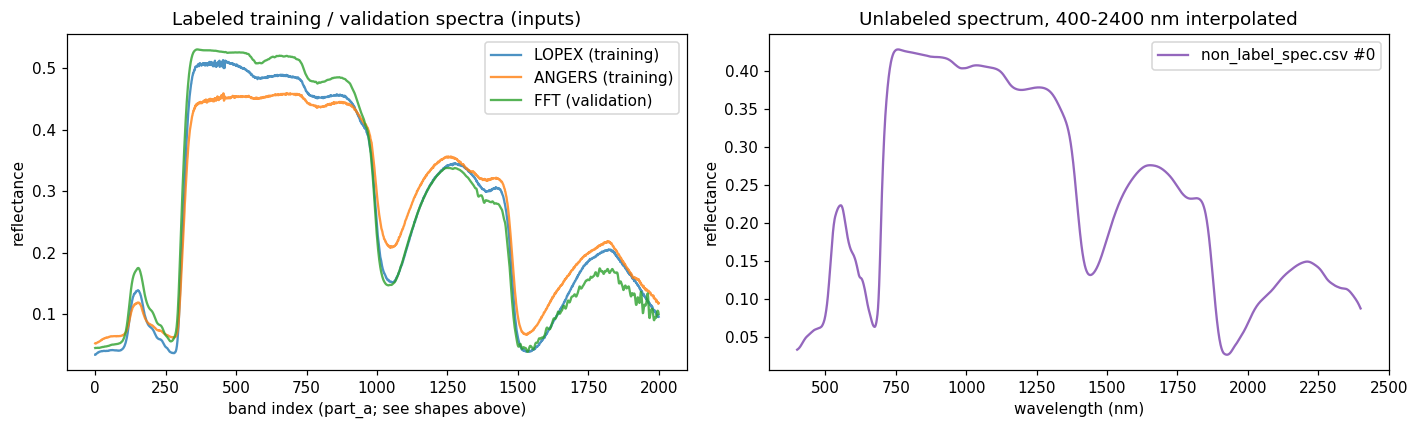

part_a: (594, 1, 2001) | part_b (unlabeled): (16765, 2001)


In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4), dpi=110)
for row, label, color in [(0, "LOPEX (training)", "tab:blue"),
                          (part_a.shape[0] // 2, "ANGERS (training)", "tab:orange"),
                          (-1, "FFT (validation)", "tab:green")]:
    axes[0].plot(part_a[row, 0].cpu().numpy(), alpha=0.8, label=label, color=color)
axes[0].set_xlabel("band index (part_a; see shapes above)")
axes[0].set_ylabel("reflectance")
axes[0].set_title("Labeled training / validation spectra (inputs)")
axes[0].legend()

wavelengths = np.arange(400, 2401, 1)
axes[1].plot(wavelengths, part_b[0], color="tab:purple", label="non_label_spec.csv #0")
axes[1].set_xlabel("wavelength (nm)")
axes[1].set_ylabel("reflectance")
axes[1].set_title("Unlabeled spectrum, 400-2400 nm interpolated")
axes[1].legend()
plt.tight_layout()
plt.show()
print("part_a:", tuple(part_a.shape), "| part_b (unlabeled):", tuple(part_b.shape))


## The encoder: multi-head attention network (pinned author code)

Verbatim author `Encoder`: six attention heads, each a bias-free `Linear(2001 → 2001)` with sigmoid attention weights multiplied element-wise onto the input spectrum, then a per-head `Linear(2001 → 1)` with sigmoid. The six head outputs pass through a final `Linear(6 → 6)` sigmoid layer and are multiplied back — the output is the normalized six-trait vector (N, Cab, Car, Cbrown, Cw, Cm), each in [0, 1].

**Japanese:** 著者コードのままのエンコーダ：6つのアテンションヘッドがスペクトルから6つのPROSPECT5形質（正規化0–1）への写像を学習します。


In [ ]:
# @title Encoder setup
Tensor = torch.FloatTensor

def expend_angels(cc,dim_n,output_size):
    return(cc.expand([dim_n,output_size]))

class Encoder(nn.Module):
    def __init__(self, input_size=2001, hidden_size=2001, output_size=1, heads=6):
        super(Encoder, self).__init__()

        self.flatten = nn.Flatten()  # Layer to flatten the output
        self.heads = heads  # Number of attention heads

        # Define attention layers for each head
        self.attention_layers = nn.ModuleList([
            nn.Sequential(
                nn.Linear(input_size, hidden_size, bias=False),  # Linear layer without bias for attention
                nn.Sigmoid()  # Sigmoid activation to scale attention weights between 0 and 1
            ) for _ in range(heads)
        ])

        # Define output layers for each head
        self.end_layers = nn.ModuleList([
            nn.Sequential(
                nn.Linear(hidden_size, output_size),  # Linear layer to reduce the hidden_size to output_size
                nn.Sigmoid()  # Optional sigmoid activation for the final output
            ) for _ in range(heads)
        ])

        # Final layer to combine the multiple attention heads
        self.final_layer = nn.Sequential(
            nn.Linear(heads, heads),  # Linear layer to combine attention heads
            nn.Sigmoid()  # Optional sigmoid activation for the final result
        )

    def forward(self, x):
        outputs = []

        # Loop through each attention head
        for i in range(self.heads):
            # Apply attention layer for the current head
            attention_weights = self.attention_layers[i](x)
            # Element-wise multiplication of attention weights and input
            weighted_x = torch.multiply(attention_weights, x)
            # Pass through the end layer for the current head
            output = self.end_layers[i](weighted_x)
            outputs.append(output)

        # Concatenate the outputs from all heads along the feature dimension
        concatenated_output = self.flatten(torch.cat(outputs, dim=1))

        # Apply final combination layer for all attention heads
        final_attention_weights = self.final_layer(concatenated_output)
        # Element-wise multiplication of the attention output and the combined heads
        final_output = torch.multiply(final_attention_weights, concatenated_output)

        return final_output


## The full-physics PROSPECT5B decoder (pinned author code)

Verbatim author `Decoder` (the default, fully physics-based variant): given normalized traits it un-normalizes them, computes per-layer absorption with the coefficient matrix, the `tav` transmissivities at 40°/90° incidence, the plate-model `xp`/`yp` terms, `plate_torch` reflectance, and a trainable `ratio_w` (clamped to [0.0001, 1]) mixing parameter. It returns `(rho, rho.detach())` — the second output supports the module-replacement loss. Based on the CCRTM R package C++ PROSPECT5.

**Japanese:** 著者コードのままのフル物理PROSPECT5Bデコーダ：形質から吸収係数・`tav`・プレートモデルを経てスペクトル反射率を再構成します。`ratio_w` は学習可能な混合パラメータです。


In [ ]:
# @title the full decoder
class Decoder(nn.Module):
    def __init__(self, alpha=torch.tensor(40).to(device), th_CoefMat=Variable(torch.tensor(CoefMat_3).to(torch.float32)).to(device),\
                 input_size=2101-100, output_size=2101-100, ratio_w=torch.tensor(0.5)):
        """
        This class implements a neural network model based on the PROSPECT model to simulate light interaction with leaves.

        Parameters:
        - alpha: angle of light incidence (in degrees)
        - th_CoefMat: matrix of coefficients that relate leaf traits to spectral properties
        - input_size: input size of the model (number of features)
        - output_size: output size of the model (number of spectral bands)
        - ratio_w: a trainable parameter that controls the ratio of direct vs. diffuse light components
        """
        super(Decoder, self).__init__()

        # Trainable parameter to control the ratio of direct/diffuse light, clamped to [0.0001, 1.0]
        self.ratio_w = nn.Parameter(torch.clamp(ratio_w, 0.0001, 1.0))
        self.alpha = alpha
        self.th_CoefMat = th_CoefMat
        self.n = n  # Refractive index for the leaf
        self.output_size = output_size
        self.input_size = input_size

    def forward(self, traits):
        """
        Forward pass of the model. It calculates the spectral reflectance based on input traits.

        Parameters:
        - traits: leaf traits (e.g., leaf structure, water content, chlorophyll, etc.)

        Returns:
        - rho: predicted reflectance of the leaf
        """
        n = self.n[:self.output_size]  # Use refractive index values up to the output size
        output_size = self.output_size
        th_CoefMat = self.th_CoefMat[:, 1:][:output_size, :]  # Coefficient matrix for spectral properties

        # Normalize the traits to fit the model's expected input distribution
        traits = normlization_torch(traits, fitting=False)

        # Split traits into the number of layers (N) and other leaf characteristics
        N, traits = traits[:, 0], traits[:, 1:]

        # Calculate the optical thickness alpha by dividing traits by the number of layers N
        alpha = torch.div(traits.T, N).T

        # Calculate the transmittance and reflectance for different angles (e.g., 40° and 90°)
        t12 = tav(self.alpha, n)  # Transmission at 40°
        tav90n = tav(torch.tensor(90), n)  # Transmission at 90°
        t21 = tav90n / pow(n, 2)  # Transmission when light moves back through the leaf
        r12 = 1 - t12  # Reflectance at the top layer
        r21 = 1 - t21  # Reflectance at the bottom layer

        # Calculate xp and yp, which are used in the plate model
        xp = t12 / tav90n
        yp = xp * (tav90n - 1) + 1 - t12

        # Calculate the sum product of the normalized traits and the abosorption coefficient matrix
        batch_num = traits.size()[0]
        if len(alpha.shape) == 2:
            k_pd = torch.matmul(alpha, th_CoefMat.t())
        else:
            k_pd = torch.matmul(alpha.unsqueeze(0), th_CoefMat.t())

        k_pdd = k_pd

        # Calculate the transmittance of the leaf (trans_rtm) based on the optical thickness
        trans_rtm = (1 - k_pdd) * exp(-k_pdd) + square(k_pdd) * exp1(k_pdd.detach().cpu()).to(device).squeeze()

        # Call the plate model function to get the reflection (rho), we only use rho in ths study
        rho = plate_torch(trans_rtm, r12, t12, t21, r21, xp, yp, N, print_both=False)

        # Return the reflectance and a detached version for further use
        return rho, rho.detach()
        # Decoder have two output. One is the similation after NN completely
        # replaces the specified module, and the other is the output after mixing
        # the specified module and the original process module results through adaptive weights.

## Train the PINN (pinned author loop, demo-adapted scale)

The author's multi-objective training loop with **documented scale adaptations only**: seed **55 only** (author looped 55–59), `range(nepochs)` with `nepochs=1001` (author hard-coded 20,000; the README's quick demo is ~1000), and the **default `Decoder`** (the author's cell instantiated `Decoder_tran`; the README's default learning rates 1e-4 encoder / 1e-5 decoder are kept). Each iteration draws 20 labeled LOPEX/ANGERS spectra and 400 unlabeled spectra and minimizes: direct spectral reconstruction (from true traits), encoder–decoder reconstruction, unlabeled reconstruction, module-replacement consistency, trait reconstruction, and cycle consistency (weighted 1/10). Cbrown labels are replaced by the encoder's own prediction (`context_data_y[:, 3] = ... .detach()`), as in the author code. Progress and validation MSE print every 250 epochs.

**Japanese:** 著者のマルチオブジェクティブ学習ループを、シード55の単一実行・約1000エポック・デフォルトの物理デコーダで実行します（論文は20,000エポック・5シード）。損失の構成とバッチサイズは著者コードのままです。250エポックごとに検証MSEを表示します。


In [ ]:
datecoding = '2012'  # author notebook cell 21, verbatim: tag used in checkpoint filenames
## @title Training the autoencoder with checkpoints

# Initialize variables
times = 0
ex_ratio = 0.4
focal_traits = 'encoder'
part_b = cc_list  # Data
## Number of epochs
nepochs=1001

# Define checkpoint file
checkpoint_file = f'checkpoint_{focal_traits}.pt'

from torch.utils.data import DataLoader, TensorDataset

# Convert `part_b` to tensor if necessary
if not isinstance(part_b, torch.Tensor):
    part_b = torch.tensor(part_b, dtype=torch.float32)


# Check tensor dimensions
print("Shape of part_a:", part_a.shape)
print("Shape of part_b:", part_b.shape)


for ii_index in range(55, 56):  # DEMO: single seed (author looped 55..59)
    record = []
    seed = ii_index

    # Set random seeds
    random.seed()
    torch.manual_seed(torch.initial_seed())
    torch.manual_seed(seed)
    random.seed(seed)

    # Instantiate models and optimizers
    # Switch the model at here
    model_yin = Encoder().to(device)
    # Here are the other candidates
    #model_yin = Decoder_tran().to(device)
    #model_yin = Encoder_plate().to(device)
    #model_yin = Decoder_both().to(device)





    model_yang = Decoder().to(device)  # DEMO: default full-physics PROSPECT5B decoder (README 'default' row)
    criterion = torch.nn.MSELoss(reduction='sum')
    optimizer = torch.optim.AdamW(model_yin.parameters(), lr=1e-4)
    optimizer2 = torch.optim.AdamW(model_yang.parameters(), lr=1e-5)

    # Recommended learning rates for each model:
    # Format: model_name  |  optimizer1_lr  |  optimizer2_lr
    # -------------------------------------------------------
    # default            |     1e-4         |     1e-5
    # both               |     1e-4         |     1e-5
    # plate              |     1e-4         |     1e-5
    # tran               |     1e-4         |     1e-4


    ## restart if there is a saved checkpoint, otherwise start at 0
    #start_epoch = load_checkpoint()
    start_epoch = 0

    # Training loop with checkpoint saving
    for iterations in range(nepochs):  # DEMO: nepochs=1001 (README quick demo; paper used 20000)
            # Generate random permutations of data indices
            perm = torch.randperm(part_a.shape[0])
            perm2 = torch.randperm(part_b.shape[0])

            # Sampling the data batches
            idx = perm[:20]
            idx2 = perm2[:400]

            # Set models to training mode
            model_yin.train()
            model_yang.train()

            context_data_x = part_a[idx]
            context_data_y = part_a_label[idx]

            noised_data = part_b[idx2]
            noised_data = to_cuda(noised_data)

            # Yin predictions
            y_yin_pred1 = model_yin(context_data_x)
            y_yin_pred2 = model_yin(noised_data)
            context_data_y[:, 3] = y_yin_pred1[:, 3].detach()

            # LOSS 1: Encoder spectral reconstruction
            y_yang_pred1, _ = model_yang(y_yin_pred1)
            inversion_loss1 = torch.nn.MSELoss()(y_yang_pred1, context_data_x)

            # LOSS 2: Direct spectral reconstruction
            y_yang_pred0, y_yang_pred0b = model_yang(context_data_y.detach())
            inversion_loss0 = torch.nn.MSELoss()(y_yang_pred0, context_data_x)

            # LOSS 3: Unlabeled spectra reconstruction
            y_yang_pred2, _ = model_yang(y_yin_pred2)
            inversion_loss2 = torch.nn.MSELoss()(y_yang_pred2, noised_data)

            # LOSS 4: Cycle Consistency Loss
            y_yin_pred3 = model_yin(y_yang_pred2)
            cycle_loss = torch.nn.MSELoss()(y_yin_pred2, y_yin_pred3)

            # LOSS 5: Module replacement loss
            inversion_loss3 = torch.nn.MSELoss()(y_yang_pred0b, context_data_x)

            # LOSS 6: Trait reconstruction
            y_yin_pred1_valid = y_yin_pred1#[:, valid_columns_indices]
            context_data_y_valid = context_data_y
            traits_loss = torch.nn.MSELoss()(y_yin_pred1_valid, context_data_y_valid)

            # Zero gradients
            optimizer.zero_grad()
            optimizer2.zero_grad()

            # Calculate total loss and backpropagate
            total_loss = (inversion_loss3 + inversion_loss0 + inversion_loss2 +
                          inversion_loss1 + traits_loss + cycle_loss / 10)
            total_loss.backward()

            # Update weights
            optimizer.step()
            optimizer2.step()

            # Update epoch loss tracker
            #total_loss_epoch += total_loss.item()
            #batch_count += 1

            # Average epoch loss
            #avg_loss = total_loss_epoch / batch_count

            # Record losses for analysis
            ## inversion_loss0: Spectral reconstruction with original traits
            ## inversion_loss1: Spectral reconstruction
            ## inversion_loss2: Unlabeled spectra reconstruction
            ## inversion_loss3: Module replacement loss
            ## traits_loss: Trait reconstruction loss
            ## cycle_loss: Cycle Consistency Loss
            record.append([inversion_loss0.item(), inversion_loss1.item(),
                           inversion_loss2.item(), inversion_loss3.item(),
                           traits_loss.item(), cycle_loss.item()])


            # Print losses for current epoch
            print(
            f'\r iterations: {iterations} | Total loss: {total_loss:.7f} | Trait reconstruction loss: {traits_loss.item():.7f} '
            f'| Spectral reconstruction (trait-based) loss: {inversion_loss0.item():.7f} | Encoder-Decoder reconstruction Loss: {inversion_loss1.item():.7f} '
            f'| Unlabeled spectra reconstruction loss: {inversion_loss2.item():.7f}',
            end=''
            )


            if iterations % 250 == 0 or iterations == nepochs - 1:  # DEMO: report every 250 epochs
                model_yin.eval()
                model_yang.eval()

                save_checkpoint(iterations, model_yang, model_yin, optimizer, optimizer2, total_loss)
                mse_values = [compute_mse(model_yin, data, labels) for data, labels in datasets_all]
                sum_table = np.array(mse_values)

                # Calculate mean of each feature
                cab, car, cw, cm = np.nanmean(sum_table[:, 1:], axis=0)
                print(f'\nCab: {cab:.5f}, Car: {car:.5f}, Cw: {cw:.5f}, Cm: {cm:.5f}, Checkpoint saved. \n')

    # Save model checkpoints
    torch.save(model_yang.state_dict(), f'pinn_decoder{ii_index}_{focal_traits}_{datecoding}.pt')
    torch.save(model_yin.state_dict(), f'pinn_encoder{ii_index}_{focal_traits}_{datecoding}.pt')


Shape of part_a: torch.Size([594, 1, 2001])
Shape of part_b: torch.Size([16765, 2001])


 iterations: 0 | Total loss: 0.0388654 | Trait reconstruction loss: 0.0202247 | Spectral reconstruction (trait-based) loss: 0.0031757 | Encoder-Decoder reconstruction Loss: 0.0079644 | Unlabeled spectra reconstruction loss: 0.0043245

Checkpoint saved at epoch 0

Cab: 0.03369, Car: 0.04231, Cw: 0.00609, Cm: 0.03967, Checkpoint saved. 



 iterations: 1 | Total loss: 0.0294235 | Trait reconstruction loss: 0.0158553 | Spectral reconstruction (trait-based) loss: 0.0022727 | Encoder-Decoder reconstruction Loss: 0.0048992 | Unlabeled spectra reconstruction loss: 0.0041222

 iterations: 2 | Total loss: 0.0278104 | Trait reconstruction loss: 0.0150162 | Spectral reconstruction (trait-based) loss: 0.0024361 | Encoder-Decoder reconstruction Loss: 0.0042111 | Unlabeled spectra reconstruction loss: 0.0037071

...

 iterations: 995 | Total loss: 0.0138208 | Trait reconstruction loss: 0.0011380 | Spectral reconstruction (trait-based) loss: 0.0045735 | Encoder-Decoder reconstruction Loss: 0.0027168 | Unlabeled spectra reconstruction loss: 0.0007791

 iterations: 997 | Total loss: 0.0087590 | Trait reconstruction loss: 0.0019049 | Spectral reconstruction (trait-based) loss: 0.0022242 | Encoder-Decoder reconstruction Loss: 0.0015198 | Unlabeled spectra reconstruction loss: 0.0008384

 iterations: 999 | Total loss: 0.0116510 | Trait reconstruction loss: 0.0032638 | Spectral reconstruction (trait-based) loss: 0.0028587 | Encoder-Decoder reconstruction Loss: 0.0018595 | Unlabeled spectra reconstruction loss: 0.0007682

 iterations: 1000 | Total loss: 0.0137049 | Trait reconstruction loss: 0.0037305 | Spectral reconstruction (trait-based) loss: 0.0033521 | Encoder-Decoder reconstruction Loss: 0.0023187 | Unlabeled spectra reconstruction loss: 0.0009023

Checkpoint saved at epoch 1000

Cab: 0.00783, Car: 0.00595, Cw: 0.00151, Cm: 0.00701, Checkpoint saved. 



## Multi-objective loss curves (pinned author code)

Verbatim author cell: Gaussian-smooths (`sigma=10`) the recorded per-iteration losses and plots all six components — direct spectral reconstruction, encoder spectra reconstruction, unlabeled spectra reconstruction, module replacement, trait reconstruction, and cycle consistency.

**Japanese:** 著者コードのまま：6つの損失成分をガウス平滑化（sigma=10）してプロットします。


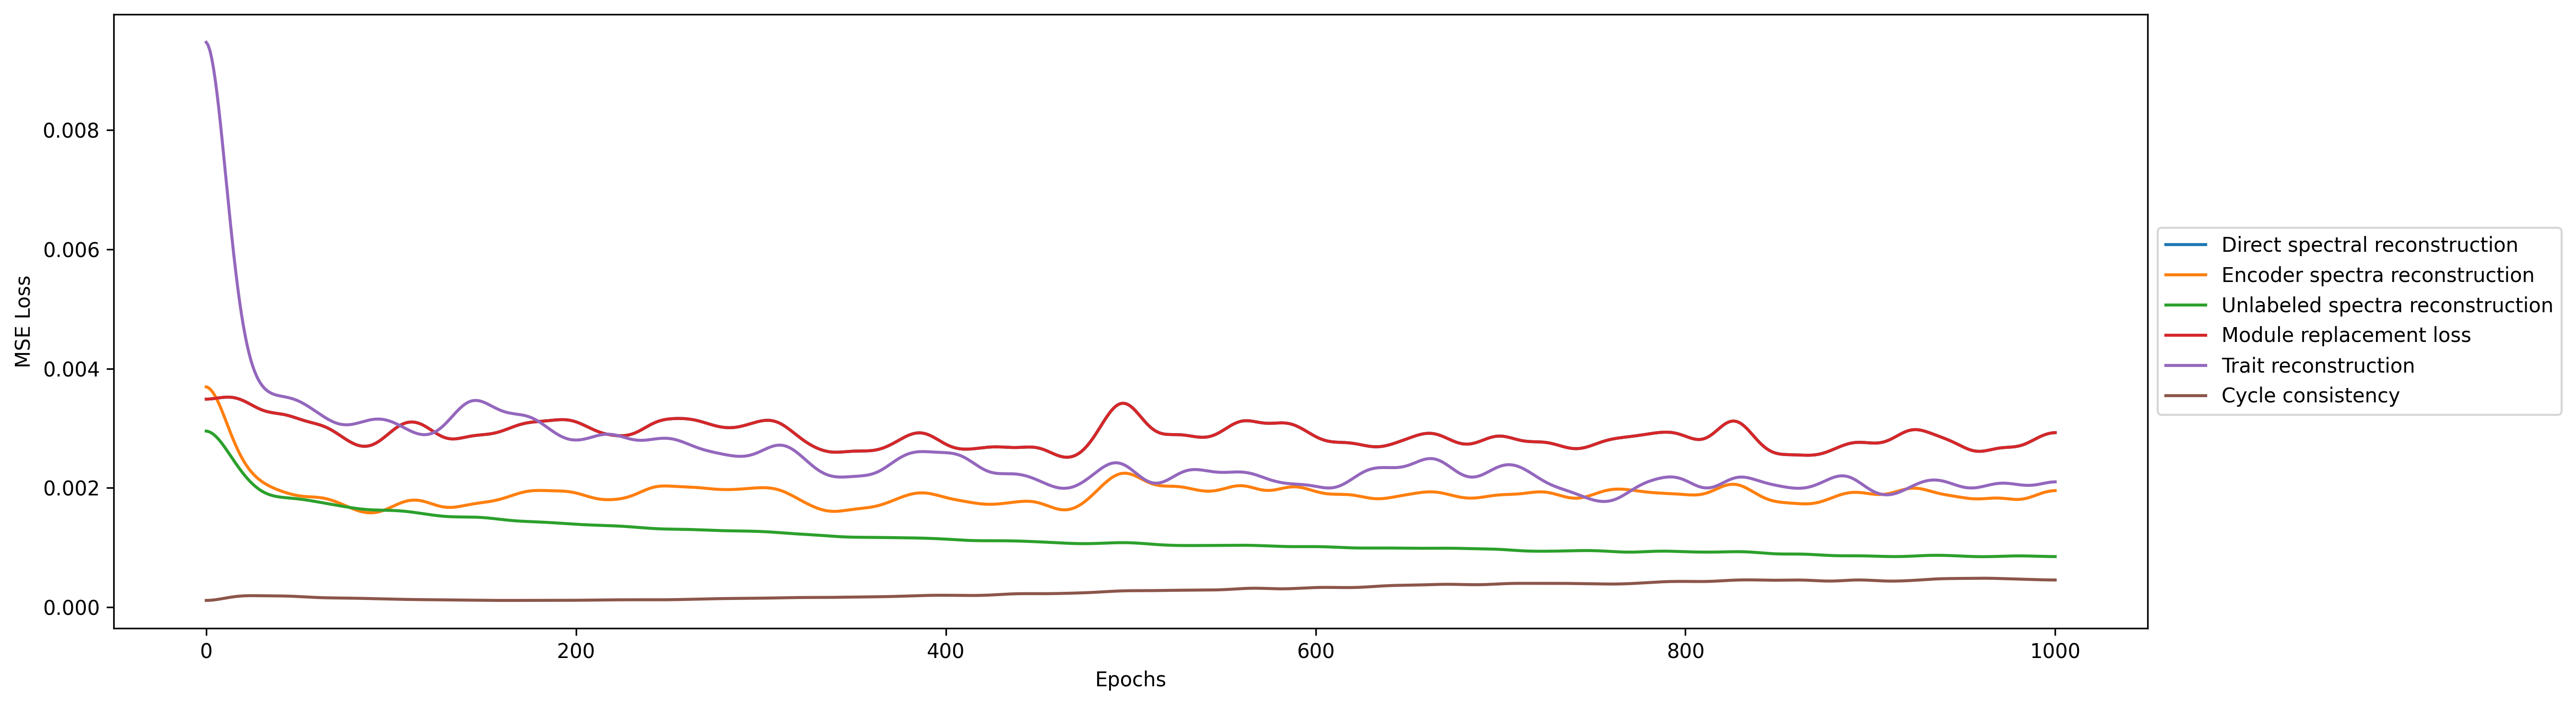

In [ ]:
# @title

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

## Recall that record has
## inversion_loss0: Dirtect spectral reconstruction
## inversion_loss1: Encoder spectral reconstruction
## inversion_loss2: Unlabeled spectra reconstruction
## inversion_loss3: Module replacement loss
## traits_loss: Trait reconstruction loss
## cycle_loss: Cycle Consistency Loss

record = np.array(record)

# Apply Gaussian smoothing (sigma defines the amount of smoothing)
smoothed_record = gaussian_filter1d(record, sigma=10, axis=0)

# Create the plot
plt.figure(figsize=(18, 5), dpi=300)

# Plot each loss component
plt.plot(smoothed_record)

plt.legend(['Direct spectral reconstruction', 'Encoder spectra reconstruction', 'Unlabeled spectra reconstruction',
            'Module replacement loss', 'Trait reconstruction', 'Cycle consistency'],
           loc='center left', bbox_to_anchor=(1, 0.5))

plt.xlabel('Epochs')
plt.ylabel('MSE Loss')

plt.tight_layout()

plt.show()


## Observed vs. predicted leaf traits on held-out sites (pinned author code)

Verbatim author validation cell: runs the trained encoder on the training data and on each held-out validation set (5 stochastic passes averaged, as in the author code), and draws `plot_summ_er_tr` observed-vs-predicted panels for Cab, Car, Cw, Cm with per-dataset regression lines, plus Pearson-r² and relative-MAPE annotations and the printed rmse/r2 table. Grey points are LOPEX+ANGERS (training); colors are the five validation sites.

**Japanese:** 著者コードのまま：学習データと5つの検証サイトについて観測値vs予測値の散布図（Cab, Car, Cw, Cm）を描画し、r²とMAPEを注記します。灰色は学習データ（LOPEX+ANGERS）、色付きは検証サイトです。


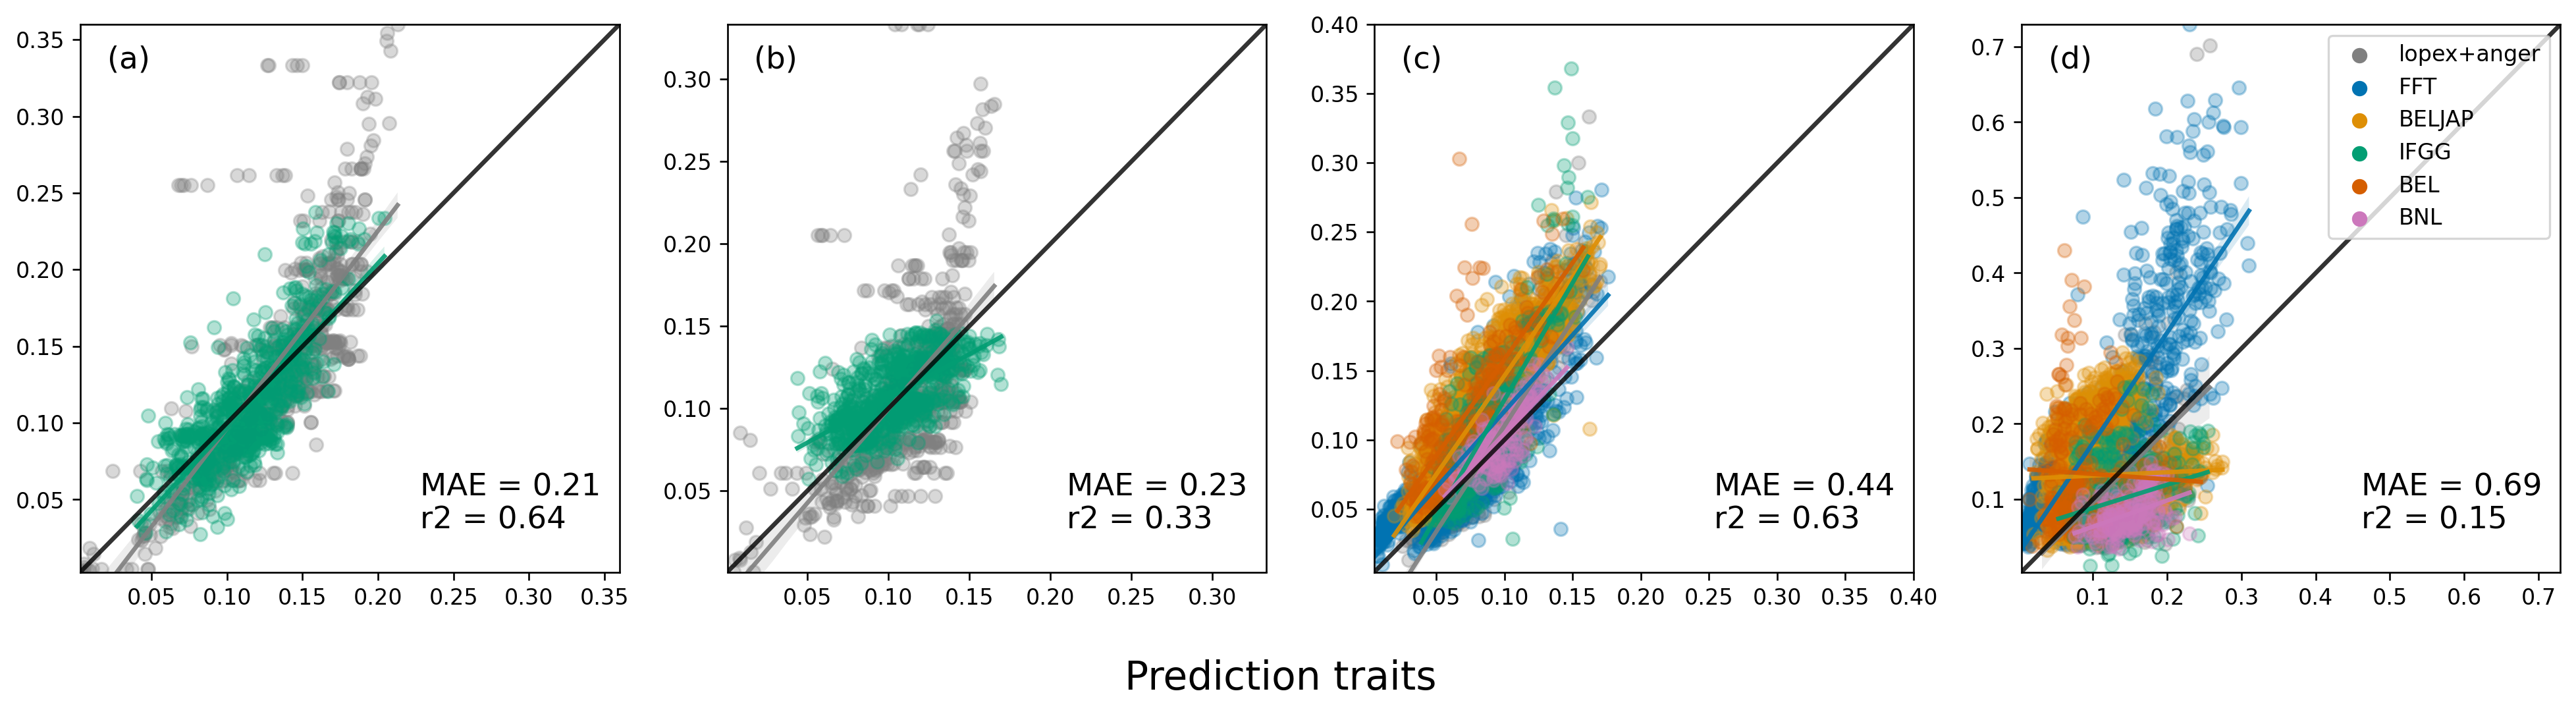

encoder :
                        rmse        r2  r2_score
Cab ($\mu g/cm^2$)  0.001232  0.635954  0.614383
Car ($\mu g/cm^2$)  0.001067  0.333988  0.319747
Cw ($g/cm^2$)       0.001699  0.629968  0.319192
Cm ($g/cm^2$)       0.006473  0.146656  0.050784


In [ ]:
# @title Plot the obeserved vs predicted

Y_columns = [
    r'nold (N)',                        # Leaf structure parameter (N)
    r'Cab ($\mu g/cm^2$)',              # Chlorophyll a+b content in ug/cm^2 (Cab)
    r'Car ($\mu g/cm^2$)',              # Carotenoids content in ug/cm^2 (Car)
    r'cbrown (arbitrary units)',        # Brown pigments content in arbitrary units (Cbrown)
    r'Cw ($g/cm^2$)',                   # Equivalent water thickness in g/cm^2 (Cw)
    r'Cm ($g/cm^2$)'                    # Leaf dry matter content in g/cm^2 - lma - (Cm)
]


# Loop over models we only hae one model in this example
for i_num, focal_model in enumerate([focal_traits]):
    # Initialize lists for tracking mean and variance
    mean_list_train, sd_list_train, sub_all = [], [], []

    # Model evaluation on part_a
    model_yin.eval()

    # Run model on part_a data and store results
    predictions = model_yin(part_a).detach().cpu().numpy()
    sub_all.append(predictions)

    # Convert to numpy array
    sub_all = np.array(sub_all)

    # Compute mean and variance over specific columns (1, 2, 4, 5)
    mean_list_train = np.mean(sub_all, axis=0)[:, [1, 2, 4, 5]]
    sd_list_train = np.var(sub_all, axis=0)[:, [1, 2, 4, 5]]

    mean_list, sd_list = [], []

    # Loop through datasets in validationsets
    for data in x_tables:
        sub_all = []

        # Perform 5 iterations 5 traits, n , car, cab, cw and cm
        for iteration in range(5):
            model_yin.eval()
            sub_all.append(model_yin(data).detach().cpu().numpy())

        # Convert to numpy array and compute mean and variance
        sub_all = np.array(sub_all)
        # just focus on car, cab, cw and cm
        mean_list.append(np.mean(sub_all, axis=0)[:, [1, 2, 4, 5]])
        sd_list.append(np.var(sub_all, axis=0)[:, [1, 2, 4, 5]])

    # Plot the summarized error for training and validation
    plot_summ_er_tr(
        mean_list, label_list,
        mean_list_train, label_list_tr,
        sd_list, sd_list_train,
        'mm', np.array(Y_columns)[[1, 2, 4, 5]],
        name=focal_model.split('_')[0],
        start_r=0,
        letter=['Default'][i_num],
        fig_num=[1, 4],
        hd=True,
        pass_t = False
    )

## Small quantitative summary for FFT (notebook-added table)

A compact table for the emphasized held-out site FFT only: per-trait RMSE and Pearson-r² computed from the trained encoder's mean prediction (over 5 passes, as above). Verified in Colab: FFT's Cab/Car reference columns are all zero (no field measurements), so those rows report `n=0` and are skipped — FFT is evaluated on Cw and Cm only, consistent with the author's zero-filtering in `plot_summ_er_tr`. This is an added summary created for this notebook, **not** a published paper metric. A CSV export is written next to the notebook outputs. (Note: the author's printed table column labeled `rmse` actually holds MSE; this added table computes true RMSE and is labeled accordingly.)

**Japanese:** 強調検証サイトFFTのみの簡易まとめ表（RMSE と Pearson-r²、5回平均の予測に基づく）。Colabでの検証により、FFTの Cab/Car 参照列はすべて0（实地測定なし）のため `n=0` として除外し、Cw・Cm のみ評価します。これは本ノートブックで追加した集計であり、論文の公表指標ではありません。CSVにも出力します。


In [ ]:
import pandas as pd
from scipy.stats import pearsonr

preds = np.mean([to_np(model_yin(x_tables[0]))[:, [1, 2, 4, 5]] for _ in range(5)], axis=0)
truth = label_list[0]
rows = []
for j, trait in enumerate(["Cab", "Car", "Cw", "Cm"]):
    p, t = preds[:, j], truth[:, j]
    ok = (t != 0) & np.isfinite(t) & np.isfinite(p)
    p, t = p[ok], t[ok]
    if len(p) < 2:  # FFT has field measurements only for Cw and Cm (verified in Colab)
        rows.append({"trait": trait, "n": int(len(p)), "rmse": np.nan, "pearson_r2": np.nan})
        continue
    rows.append({"trait": trait, "n": len(p),
                 "rmse": float(np.sqrt(np.mean((p - t) ** 2))),
                 "pearson_r2": float(pearsonr(t, p)[0] ** 2)})
fft_table = pd.DataFrame(rows).set_index("trait")
display(fft_table)
fft_table.to_csv("fft_validation_summary.csv")
print("saved fft_validation_summary.csv (one held-out site, single demo run)")


,n,rmse,pearson_r2
trait,,,
Cab,0,NaN,NaN
Car,0,NaN,NaN
Cw,682,0.046219,0.594292
Cm,682,0.126396,0.656308


saved fft_validation_summary.csv (one held-out site, single demo run)


## Interpretation, validation record, and references

**What was executed.** This notebook was run top-to-bottom on a fresh Google Colab **T4 GPU** session on the validation date recorded in the accompanying report: dependency install, pinned-data download + md5 verification, author data pipeline, PINN training (seed 55, ~1000 epochs, default physics decoder), loss curves, and held-out observed-vs-predicted plots. Outputs shown are from that run; they may vary with Colab hardware/free-tier availability.

**How to read the results.** With ~1000 epochs (vs the paper's 20,000), trait predictions are expected to be noticeably noisier than the paper's published accuracy; the loss curves should still show the physics decoder reconstructing spectra from traits. The point of this demo is the *mechanism*: an attention encoder + differentiable PROSPECT5B decoder trained end-to-end on real LOPEX/ANGERS/FFT spectra.

**Differences from the paper / unverified scope.** Benchmarks (emcee MCMC inversion, PLSR), the CNN-replaced decoder variants, multi-seed averaging, and all dataset-level accuracy claims are not reproduced. The full paper text was not consulted for this demo; all scientific content comes from the pinned author code and README (see `notes/feasibility.md` in the reproduction run).

**References.**
- Sun, P. et al. (2025). Remote Sensing of Environment 329:114958. DOI 10.1016/j.rse.2025.114958
- Author code: github.com/Schimasuperbra/hybrid-leaf-traits-pinn @ 7b8d143 (MIT)
- Data: Zenodo record 22092672 (CC-BY-4.0), md5 d9157f9bcf1b10d61c352c59e7d47b19
- torchrtm: PyPI package providing the differentiable PROSPECT5B components (tav, plate_torch, load_coefmat)
- CCRTM R package (Visker, 2021) — basis of the PROSPECT5B decoder

**Japanese:** 本デモは新規のColab T4 GPUセッションで最初から最後まで実行・検証済みです。約1,000エポックのため精度は論文公表値より粗いことが期待されます。ベンチマーク（MCMC・PLSR）、CNN置換デコーダ、マルチシード平均は対象外です。すべてのデータダウンロードと科学計算はColab上で行われました。
